In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
df = pd.read_csv(
    r"C:\Users\ankitvishwakarma\Downloads\Diwali Sales Data.csv",
    encoding="latin1"
)

df.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [25]:
df.shape

(11251, 15)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.9 MB


In [27]:
df.isnull().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11251
unnamed1            11251
dtype: int64

In [29]:
## Drop columns Status and Unnamed1
df.drop(["Status","unnamed1"], axis=1,inplace=True)

In [30]:
df.isnull().sum()

User_ID              0
Cust_name            0
Product_ID           0
Gender               0
Age Group            0
Age                  0
Marital_Status       0
State                0
Zone                 0
Occupation           0
Product_Category     0
Orders               0
Amount              12
dtype: int64

In [31]:
### Drop null values
df.dropna(inplace=True)

In [32]:
df.isnull().sum()

User_ID             0
Cust_name           0
Product_ID          0
Gender              0
Age Group           0
Age                 0
Marital_Status      0
State               0
Zone                0
Occupation          0
Product_Category    0
Orders              0
Amount              0
dtype: int64

In [35]:
## Change data type
df['Amount']=df['Amount'].astype('int')

In [36]:
df['Amount'].dtypes

dtype('int64')

In [38]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='str')

In [39]:
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount
count,1.123900e+04,11239.000000,11239.000000,11239.000000,11239.000000
mean,1.003004e+06,35.410357,0.420055,2.489634,9453.610553
std,1.716039e+03,12.753866,0.493589,1.114967,5222.355168
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000
25%,1.001492e+06,27.000000,0.000000,2.000000,5443.000000
50%,1.003064e+06,33.000000,0.000000,2.000000,8109.000000
75%,1.004426e+06,43.000000,1.000000,3.000000,12675.000000
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000


### EDA (Exploratory Data Analysis)

#### Gender

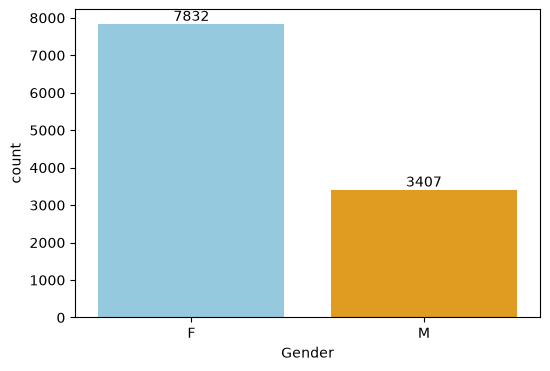

In [55]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(
    x="Gender",
    data=df,
    hue="Gender",
    palette=["skyblue", "orange"],
    legend=False
)

for bars in ax.containers:
    plt.bar_label(bars)

plt.show()

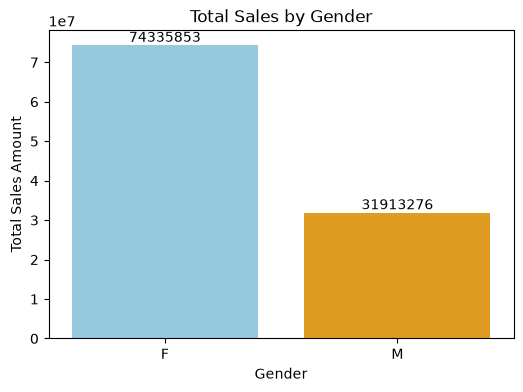

In [52]:
sales_gen = df.groupby(
    ['Gender'], as_index=False
)['Amount'].sum().sort_values(
    by='Amount', ascending=False
)

plt.figure(figsize=(6, 4))

ax = sns.barplot(
x='Gender',
y='Amount',
data=sales_gen,
hue='Gender',
palette=['skyblue', 'orange'],
legend=False
)

for bars in ax.containers:
    plt.bar_label(bars, fmt='%.0f')

plt.xlabel('Gender')
plt.ylabel('Total Sales Amount')
plt.title('Total Sales by Gender')
plt.show()

### Age

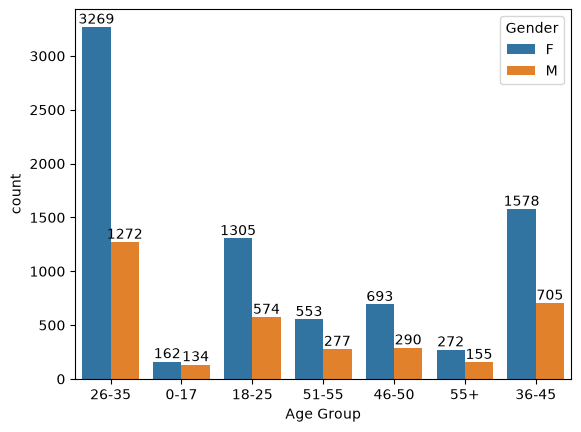

In [60]:
ax=sns.countplot(data=df, x='Age Group',hue='Gender' )
for bars in ax.containers:
    ax.bar_label(bars)

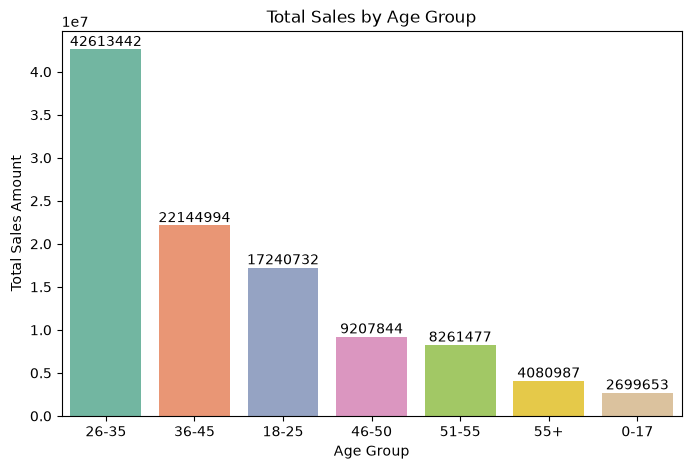

In [68]:
##  Total Amount vs Age Group

sales_age = df.groupby(['Age Group'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)

plt.figure(figsize=(8, 5))

ax = sns.barplot(x='Age Group', y='Amount', data=sales_age, hue='Age Group', palette='Set2',legend=False)

for bars in ax.containers:
    plt.bar_label(bars, fmt='%.0f')

plt.xlabel('Age Group')
plt.ylabel('Total Sales Amount')
plt.title('Total Sales by Age Group')
plt.show()

### State

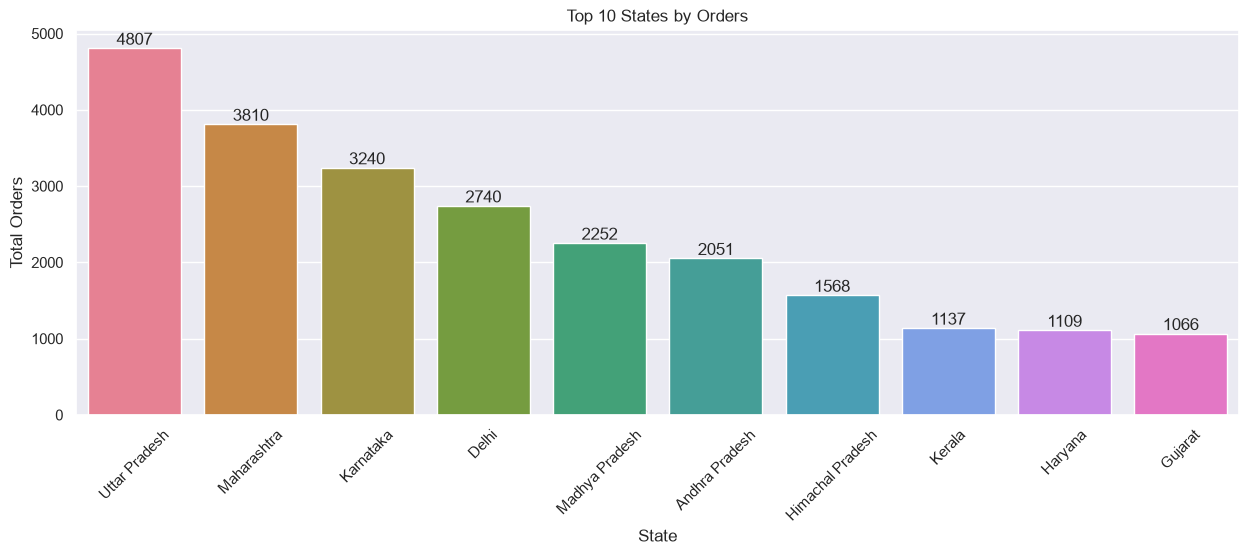

In [78]:
## Total Numbers of Orders from top 10 states

sales_state = df.groupby(['State'], as_index=False)['Orders'].sum().sort_values( by='Orders', ascending=False).head(10)

sns.set(rc={'figure.figsize': (15, 5)})

ax = sns.barplot(data=sales_state, x='State', y='Orders', hue='State', palette='husl', legend=False)

for bars in ax.containers:
    ax.bar_label(bars)

plt.xlabel('State')
plt.ylabel('Total Orders')
plt.title('Top 10 States by Orders')
plt.xticks(rotation=45)
plt.show()

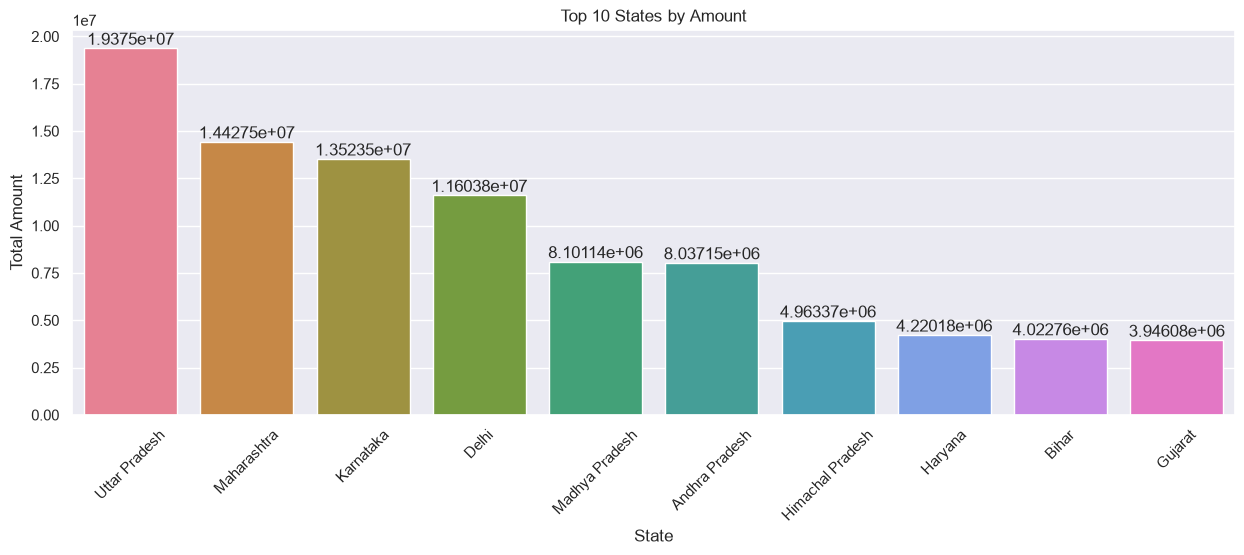

In [82]:
## Total Amount/Sales from top 10 states
import matplotlib.pyplot as plt
import seaborn as sns

sales_state = df.groupby(['State'], as_index=False)['Amount'].sum().sort_values( by='Amount', ascending=False).head(10)

sns.set(rc={'figure.figsize': (15, 5)})

ax = sns.barplot(data=sales_state, x='State', y='Amount', hue='State',  palette='husl', legend=False)

for bars in ax.containers:
    ax.bar_label(bars)

plt.xlabel('State')
plt.ylabel('Total Amount')
plt.title('Top 10 States by Amount')
plt.xticks(rotation=45)
plt.show()

### Marital State

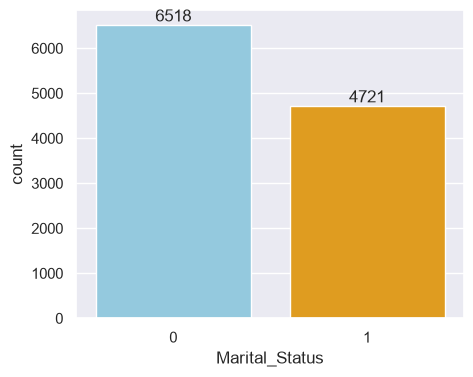

In [113]:
sns.set(rc={'figure.figsize': (5, 4)})

ax = sns.countplot(data=df, x='Marital_Status', hue='Marital_Status', palette=['skyblue', 'orange'], legend=False)

for bars in ax.containers:
    ax.bar_label(bars)

plt.show()

<Axes: xlabel='Marital_Status', ylabel='Amount'>

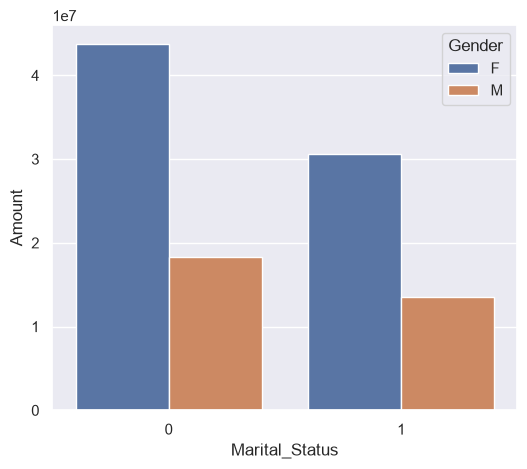

In [93]:
sales_state=df.groupby(['Marital_Status','Gender'],as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)
sns.set(rc={'figure.figsize':(6,5)})
sns.barplot(data=sales_state, x= 'Marital_Status', y='Amount', hue='Gender')

## Occupation

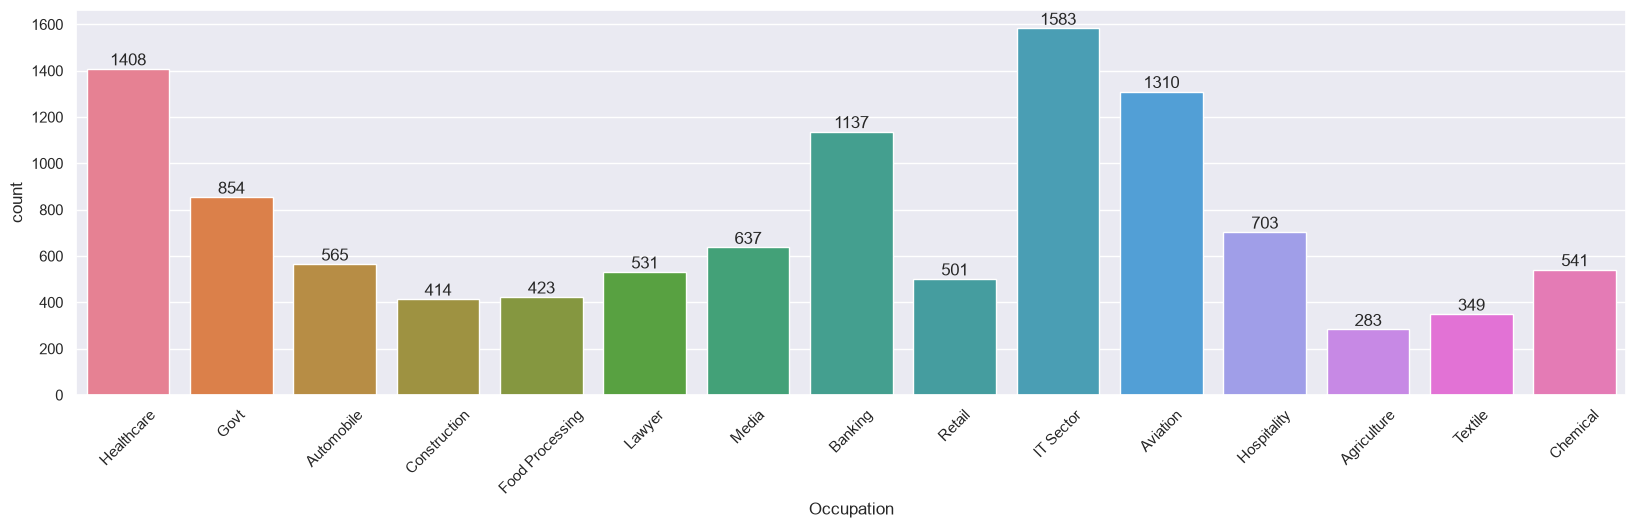

In [95]:
sns.set(rc={'figure.figsize': (20, 5)})

ax = sns.countplot(data=df, x='Occupation', hue='Occupation', palette='husl', legend=False)

for bars in ax.containers:
    ax.bar_label(bars)

plt.xticks(rotation=45)
plt.show()

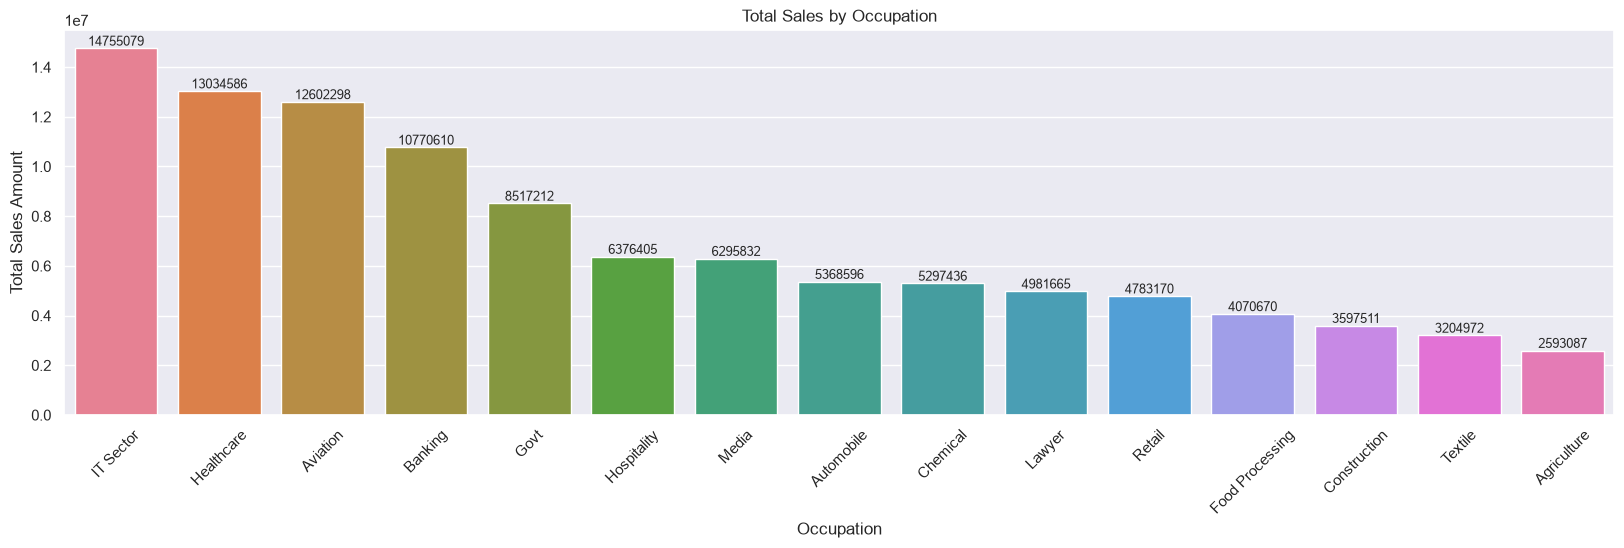

In [97]:
sales_state = df.groupby(['Occupation'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False)

sns.set(rc={'figure.figsize': (20, 5)})

ax = sns.barplot(data=sales_state, x='Occupation', y='Amount', hue='Occupation', palette='husl', legend=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f', fontsize=9)

plt.xticks(rotation=45)
plt.xlabel('Occupation')
plt.ylabel('Total Sales Amount')
plt.title('Total Sales by Occupation')
plt.show()

### Product Category

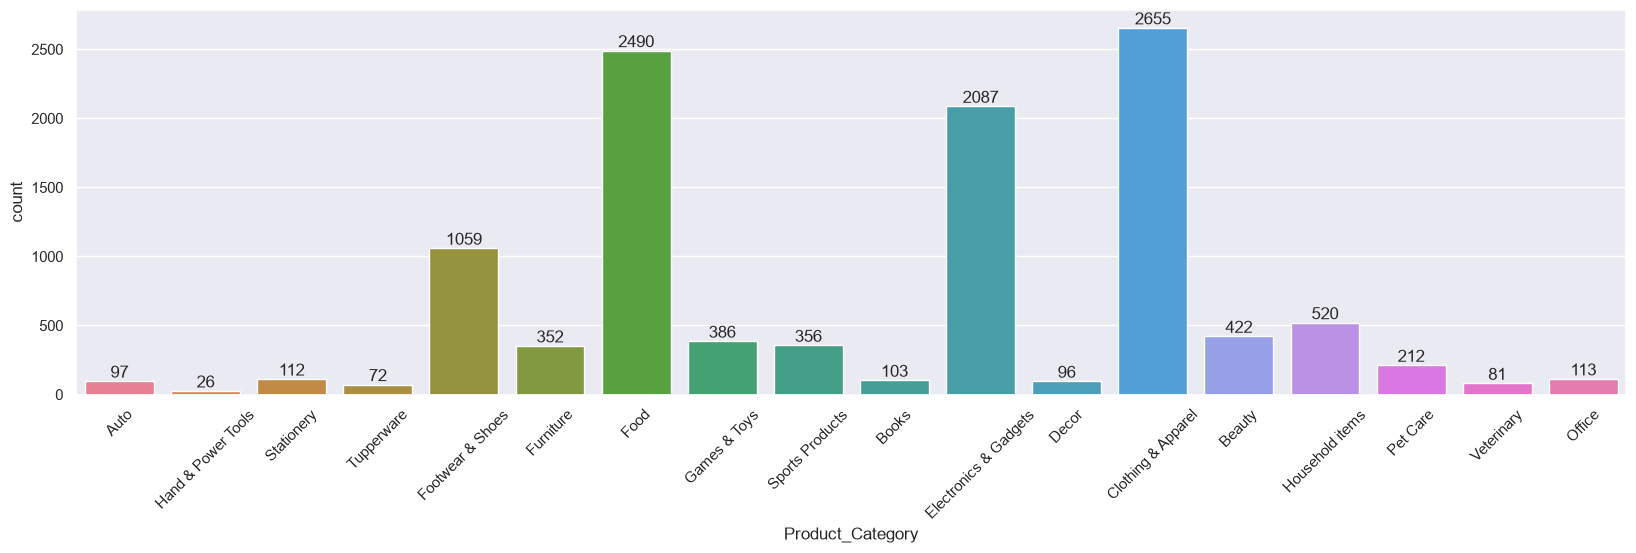

In [99]:
sns.set(rc={'figure.figsize': (20, 5)})

ax = sns.countplot( data=df, x='Product_Category', hue='Product_Category', palette='husl', legend=False)
for bars in ax.containers:
    ax.bar_label(bars)

plt.xticks(rotation=45)
plt.show()

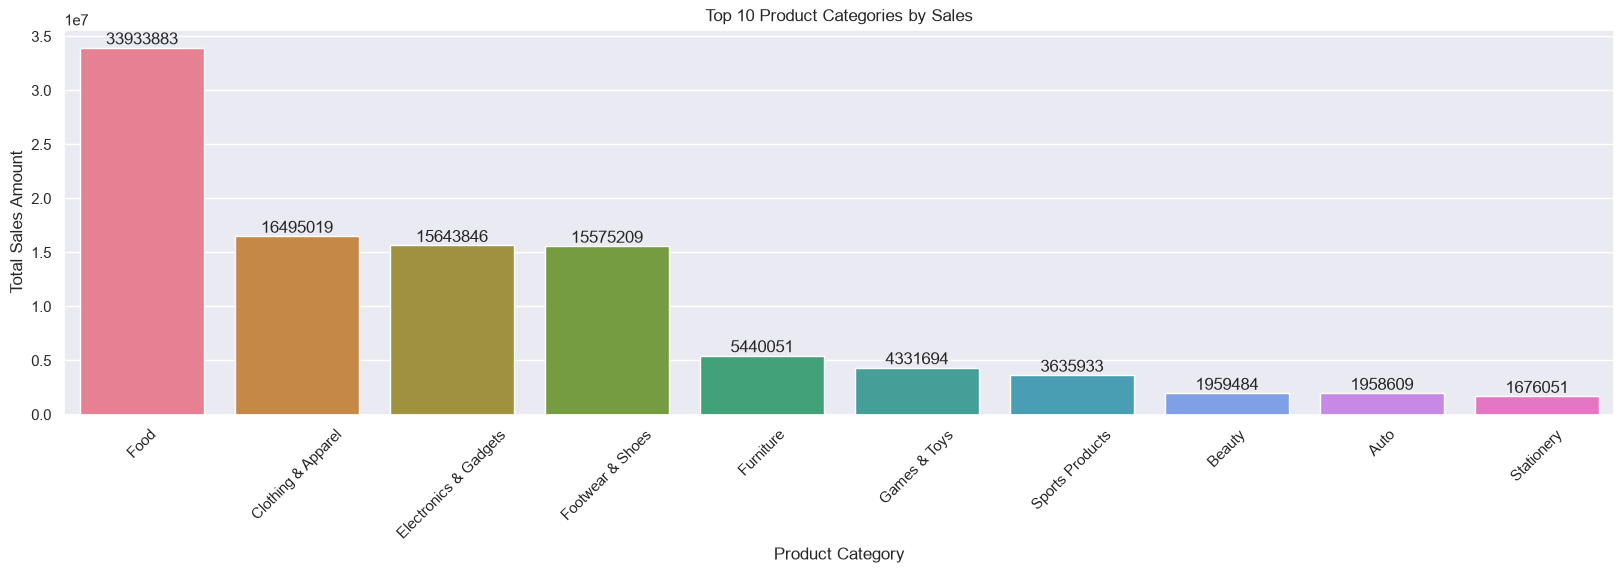

In [103]:
sales_state = df.groupby(['Product_Category'], as_index=False)['Amount'].sum().sort_values(by='Amount', ascending=False).head(10)
sns.set(rc={'figure.figsize': (20, 5)})

ax = sns.barplot( data=sales_state, x='Product_Category', y='Amount',hue='Product_Category', palette='husl',legend=False)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f')

plt.xlabel('Product Category')
plt.ylabel('Total Sales Amount')
plt.title('Top 10 Product Categories by Sales')
plt.xticks(rotation=45)
plt.show()

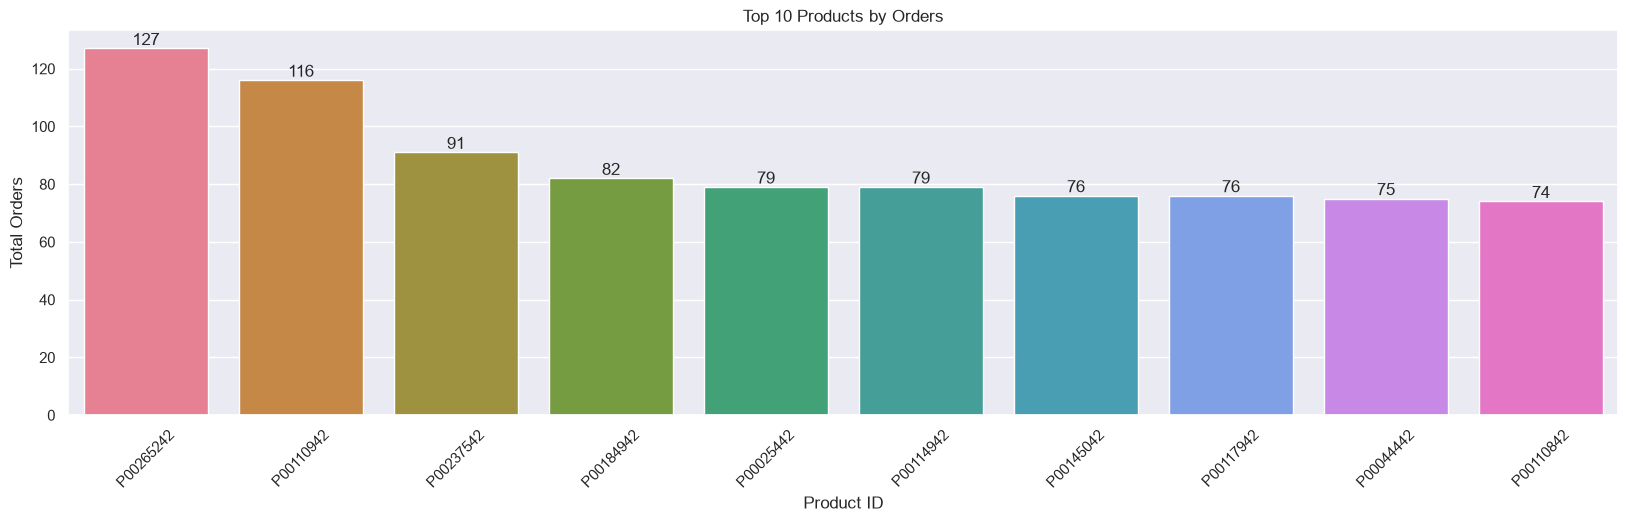

In [114]:
sales_state = df.groupby( ['Product_ID'], as_index=False)['Orders'].sum().sort_values(by='Orders', ascending=False).head(10)
sns.set(rc={'figure.figsize': (20, 5)})

ax = sns.barplot(data=sales_state, x='Product_ID', y='Orders',hue='Product_ID', palette='husl',legend=False)

for bars in ax.containers:
    ax.bar_label(bars)

plt.xlabel('Product ID')
plt.ylabel('Total Orders')
plt.title('Top 10 Products by Orders')
plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='Product_ID'>

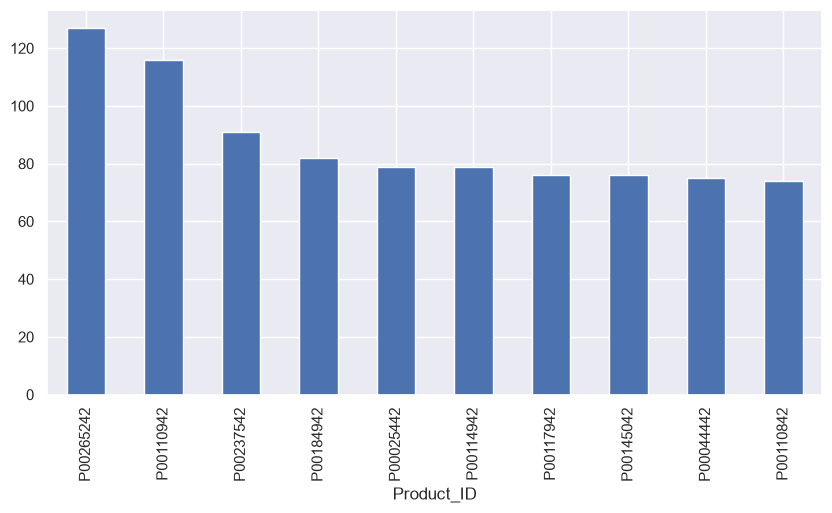

In [108]:
## Top 10  most sold products (same thing and above)
fig1,ax1=plt.subplots(figsize=(10,5))
df.groupby('Product_ID')['Orders'].sum().nlargest(10).sort_values(ascending=False).plot(kind='bar')


### Conclusion:


###### Married Women age group 25-35 yrs from UP ,Maharastra and Karnatka  working in IT ,Healthcare and Aviation are more  likly to buy product from Food, Clothing and Electronic cetegory. 

1. Gender:
Married women are an important customer segment in the dataset.
2. Age Group:
Women aged 26–35 years are more likely to purchase products.
3. State:
Customers from Uttar Pradesh (UP), Maharashtra, and Karnataka show significant purchasing activity.
4. Occupation:
Women working in IT, Healthcare, and Aviation are identified as potential target customers.
5. Product Categories:
Food, Clothing, and Electronics are the popular product categories among this customer segment.